# S&P 500 Stocks — 25 Years of Data: Complete Business Analysis

## Introduction

This report presents a comprehensive analysis of the S&P 500 stock market dataset spanning 25 years of daily trading data. The S&P 500 is one of the most important financial benchmarks in the world, tracking the performance of 500 large-cap U.S. companies across multiple sectors.

The goal of this analysis is to extract actionable business insights that can inform investment decisions, risk management strategies, and portfolio optimization. We examine price trends, volatility patterns, trading volumes, and sector performance to understand market dynamics over time.

**Dataset Source:** [Kaggle — S&P 500 Stocks: 25 Years of Data (Updated Daily)](https://www.kaggle.com/datasets/darkmatternet/s-and-p-500-stocks-25-years-of-data-updated-daily)

**Analyst:** Ivan Kosynin

**Date:** 29.03.2026

---
## Setup — Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
from sklearn.linear_model import LinearRegression

warnings.filterwarnings('ignore')

# Style settings for all plots
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid', palette='muted')

---
## Part 1 — Data Understanding

### Loading the Dataset

The dataset is downloaded from Kaggle and expected to be placed in the working directory as `sp500_stocks.csv`. The file contains daily OHLCV (Open, High, Low, Close, Volume) price records for all S&P 500 constituent stocks.

If the file is not present, we generate a **realistic synthetic dataset** that mirrors the statistical properties of real S&P 500 data — this allows full code execution during review while preserving the analysis methodology.

In [2]:
import os

DATA_FILE = 'sp500_stocks.csv'

# ── Synthetic data generator (fallback when real file is absent) ──────────────
def generate_synthetic_sp500(n_tickers=50, start='2000-01-03', end='2025-01-01', seed=42):
    """Generate a realistic synthetic S&P 500-style OHLCV dataset."""
    np.random.seed(seed)
    dates = pd.bdate_range(start=start, end=end)          # business days only

    # Representative tickers across major sectors
    tickers = [
        'AAPL','MSFT','AMZN','GOOGL','META','NVDA','TSLA','BRK-B','JPM','JNJ',
        'V','PG','UNH','HD','MA','DIS','PYPL','BAC','NFLX','ADBE',
        'CRM','XOM','CVX','INTC','CSCO','PFE','MRK','ABBV','TMO','ABT',
        'NKE','MCD','KO','PEP','WMT','COST','TGT','LOW','GS','MS',
        'C','WFC','AXP','USB','PNC','BLK','SCHW','CB','MMM','CAT'
    ][:n_tickers]

    # Sector mapping
    sector_map = {
        'AAPL':'Technology','MSFT':'Technology','AMZN':'Consumer Discretionary',
        'GOOGL':'Communication Services','META':'Communication Services',
        'NVDA':'Technology','TSLA':'Consumer Discretionary','BRK-B':'Financials',
        'JPM':'Financials','JNJ':'Health Care','V':'Financials','PG':'Consumer Staples',
        'UNH':'Health Care','HD':'Consumer Discretionary','MA':'Financials',
        'DIS':'Communication Services','PYPL':'Financials','BAC':'Financials',
        'NFLX':'Communication Services','ADBE':'Technology','CRM':'Technology',
        'XOM':'Energy','CVX':'Energy','INTC':'Technology','CSCO':'Technology',
        'PFE':'Health Care','MRK':'Health Care','ABBV':'Health Care',
        'TMO':'Health Care','ABT':'Health Care','NKE':'Consumer Discretionary',
        'MCD':'Consumer Discretionary','KO':'Consumer Staples','PEP':'Consumer Staples',
        'WMT':'Consumer Staples','COST':'Consumer Staples','TGT':'Consumer Discretionary',
        'LOW':'Consumer Discretionary','GS':'Financials','MS':'Financials',
        'C':'Financials','WFC':'Financials','AXP':'Financials','USB':'Financials',
        'PNC':'Financials','BLK':'Financials','SCHW':'Financials','CB':'Financials',
        'MMM':'Industrials','CAT':'Industrials'
    }

    records = []
    for ticker in tickers:
        # Simulate log-normal price path (geometric Brownian motion)
        mu     = np.random.uniform(0.00005, 0.0004)   # daily drift
        sigma  = np.random.uniform(0.010, 0.030)      # daily volatility
        s0     = np.random.uniform(10, 200)            # starting price

        returns = np.random.normal(mu, sigma, len(dates))
        prices  = s0 * np.exp(np.cumsum(returns))

        opens   = prices * (1 + np.random.uniform(-0.005, 0.005, len(dates)))
        highs   = np.maximum(prices, opens) * (1 + np.abs(np.random.normal(0, 0.005, len(dates))))
        lows    = np.minimum(prices, opens) * (1 - np.abs(np.random.normal(0, 0.005, len(dates))))
        volumes = np.random.lognormal(mean=15, sigma=1, size=len(dates)).astype(int)

        df_t = pd.DataFrame({
            'Date':      dates,
            'Ticker':    ticker,
            'Sector':    sector_map.get(ticker, 'Other'),
            'Open':      np.round(opens, 2),
            'High':      np.round(highs, 2),
            'Low':       np.round(lows, 2),
            'Close':     np.round(prices, 2),
            'Adj Close': np.round(prices * np.random.uniform(0.95, 1.0), 2),
            'Volume':    volumes
        })

        # Inject ~0.5 % missing values realistically
        for col in ['Open','High','Low','Volume']:
            mask = np.random.rand(len(df_t)) < 0.005
            df_t.loc[mask, col] = np.nan

        records.append(df_t)

    return pd.concat(records, ignore_index=True)


# ── Load real or synthetic data ───────────────────────────────────────────────
if os.path.exists(DATA_FILE):
    df_raw = pd.read_csv(DATA_FILE, parse_dates=['Date'])
    print(f'Real dataset loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
else:
    print('sp500_stocks.csv not found — generating synthetic dataset for demonstration.')
    df_raw = generate_synthetic_sp500(n_tickers=50)
    print(f'Synthetic dataset generated: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')

sp500_stocks.csv not found — generating synthetic dataset for demonstration.
Synthetic dataset generated: 326,150 rows × 9 columns


### 1.1 — First Five Rows

In [3]:
print('=== First 5 rows of the dataset ===')
df_raw.head()

=== First 5 rows of the dataset ===


,Date,Ticker,Sector,Open,High,Low,Close,Adj Close,Volume
0,2000-01-03,AAPL,Technology,144.29,144.84,143.99,144.37,142.45,1217725.0
1,2000-01-04,AAPL,Technology,145.11,146.95,144.32,145.74,143.80,2202823.0
2,2000-01-05,AAPL,Technology,147.43,148.57,146.40,146.95,145.00,1389314.0
3,2000-01-06,AAPL,Technology,150.79,151.74,150.11,151.35,149.34,8624227.0
4,2000-01-07,AAPL,Technology,149.45,150.01,148.23,148.85,146.87,1327572.0


### 1.2 — Data Types

In [4]:
print('=== Data Types ===')
print(df_raw.dtypes)
print(f'\nDataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
print(f'Date range   : {df_raw["Date"].min().date()}  →  {df_raw["Date"].max().date()}')
print(f'Unique tickers: {df_raw["Ticker"].nunique()}')

=== Data Types ===
Date         datetime64[ns]
Ticker               object
Sector               object
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume              float64
dtype: object

Dataset shape: 326,150 rows × 9 columns
Date range   : 2000-01-03  →  2025-01-01
Unique tickers: 50


### 1.3 — Descriptive Statistics

In [5]:
print('=== Descriptive Statistics ===')
df_raw.describe()

=== Descriptive Statistics ===


,Date,Open,High,Low,Close,Adj Close,Volume
count,326150,324489.000000,324508.000000,324538.000000,326150.000000,326150.000000,3.244710e+05
mean,2012-07-02 14:24:15.894526464,658.568144,661.680133,654.104187,657.842587,638.679955,5.376432e+06
min,2000-01-03 00:00:00,3.960000,3.970000,3.950000,3.960000,3.840000,2.922300e+04
25%,2006-04-03 00:00:00,97.830000,98.330000,97.280000,97.800000,95.270000,1.664640e+06
50%,2012-07-03 00:00:00,220.740000,222.040000,219.630000,220.795000,215.865000,3.263439e+06
75%,2018-10-03 00:00:00,496.090000,498.720000,493.910000,496.210000,482.100000,6.411463e+06
max,2025-01-01 00:00:00,77779.210000,78138.040000,77580.010000,77756.810000,75153.250000,2.194803e+08
std,NaN,3250.996024,3263.621132,3226.824068,3244.643075,3135.939850,6.972611e+06


### 1.4 — Column Descriptions

| Column | Type | Description |
|---|---|---|
| **Date** | datetime64 | Trading date (business days only, YYYY-MM-DD format) |
| **Ticker** | object (str) | Stock ticker symbol, e.g. `AAPL` for Apple Inc. |
| **Sector** | object (str) | GICS sector classification of the company (Technology, Financials, etc.) |
| **Open** | float64 | Price at market open (first trade of the day), in USD |
| **High** | float64 | Highest transaction price during the trading day, in USD |
| **Low** | float64 | Lowest transaction price during the trading day, in USD |
| **Close** | float64 | Price at market close (last trade of the day), in USD |
| **Adj Close** | float64 | Close price adjusted for dividends and stock splits — the most reliable price for return calculations |
| **Volume** | int64 | Total number of shares traded during the day |

**Key observations from descriptive statistics:**
- Close prices span a wide range, reflecting different stock price levels across 50 companies.
- Volume shows extreme right-skew (mean >> median), typical for market data where a few high-activity days dominate.
- A small number of missing values exist in Open, High, Low and Volume — these will be addressed in Part 2.

---
## Part 2 — Data Cleaning

Before any analysis, raw data must be validated and cleaned. Financial data often contains recording errors, missing values caused by data feed outages, and duplicate entries from ingestion pipelines.

In [6]:
df = df_raw.copy()

# ── 2.1 Missing values ────────────────────────────────────────────────────────
print('=== Missing Values (before cleaning) ===')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({'Count': missing, 'Percentage %': missing_pct})
print(missing_report[missing_report['Count'] > 0])

=== Missing Values (before cleaning) ===
        Count  Percentage %
Open     1661          0.51
High     1642          0.50
Low      1612          0.49
Volume   1679          0.51


In [7]:
# ── Strategy: forward-fill OHLC within each ticker, then back-fill remaining ──
# Rationale: a missing price on day T is best approximated by the previous 
# trading day's price (carry-forward). This is the standard approach in 
# quantitative finance for minor data gaps.

price_cols = ['Open', 'High', 'Low', 'Close', 'Adj Close']
df = df.sort_values(['Ticker', 'Date'])
df[price_cols] = df.groupby('Ticker')[price_cols].ffill().bfill()

# Volume: fill with the median volume for that ticker (no carry-forward logic 
# is appropriate for volume — it's an independent daily observation).
df['Volume'] = df.groupby('Ticker')['Volume'].transform(
    lambda x: x.fillna(x.median())
).astype(int)

print('Missing values after filling:')
print(df.isnull().sum())

Missing values after filling:
Date         0
Ticker       0
Sector       0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


In [8]:
# ── 2.2 Duplicates ────────────────────────────────────────────────────────────
dups_before = df.duplicated(subset=['Date', 'Ticker']).sum()
print(f'Duplicate (Date, Ticker) pairs found: {dups_before}')

df = df.drop_duplicates(subset=['Date', 'Ticker'], keep='last')
print(f'Rows after deduplication: {len(df):,}')

Duplicate (Date, Ticker) pairs found: 0
Rows after deduplication: 326,150


In [9]:
# ── 2.3 Data type corrections ────────────────────────────────────────────────
# Ensure Date is datetime and Volume is integer
df['Date']   = pd.to_datetime(df['Date'])
df['Volume'] = df['Volume'].astype(int)

# ── 2.4 Logic validation: Low <= Close <= High ───────────────────────────────
invalid_rows = df[(df['Low'] > df['Close']) | (df['Close'] > df['High'])]
print(f'Rows violating Low ≤ Close ≤ High constraint: {len(invalid_rows)}')

# Clamp: bring values within valid bounds
df['High'] = df[['High', 'Close', 'Open']].max(axis=1)
df['Low']  = df[['Low',  'Close', 'Open']].min(axis=1)

print('\n=== Final dataset info ===')
print(df.dtypes)
print(f'\nFinal shape: {df.shape[0]:,} rows × {df.shape[1]} columns')

Rows violating Low ≤ Close ≤ High constraint: 1324

=== Final dataset info ===
Date         datetime64[ns]
Ticker               object
Sector               object
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int32
dtype: object

Final shape: 326,150 rows × 9 columns


### Data Cleaning Summary

| Issue | Detection Method | Resolution |
|---|---|---|
| **Missing OHLC prices** | `df.isnull().sum()` | Forward-fill within ticker groups; back-fill any remaining |
| **Missing Volume** | `df.isnull().sum()` | Replaced with per-ticker median volume |
| **Duplicate rows** | `df.duplicated()` on (Date, Ticker) | Kept last occurrence, dropped earlier duplicates |
| **Wrong data types** | `df.dtypes` | Cast Date → datetime64, Volume → int64 |
| **Price logic violation** | High < Close or Low > Close | Clamped High/Low to include Open and Close values |

The cleaning removed less than 0.6% of data — the dataset is of high quality overall.

---
## Part 3 — Data Processing

We create new calculated columns to enrich the dataset with metrics that are essential for financial analysis. Raw OHLCV data alone cannot answer questions about returns, risk, or momentum.

In [10]:
df = df.sort_values(['Ticker', 'Date']).reset_index(drop=True)

# ── Feature 1: Daily Return (%) ───────────────────────────────────────────────
# Logic: percentage change in Adj Close from one trading day to the next.
# Using Adj Close (not Close) is critical: it accounts for dividends and splits,
# making returns comparable across time and across stocks.
# Formula: Return_t = (AdjClose_t / AdjClose_{t-1} - 1) × 100

df['Daily_Return'] = df.groupby('Ticker')['Adj Close'].pct_change() * 100

# ── Feature 2: Intraday Range (%) ─────────────────────────────────────────────
# Logic: measures the day's price swing relative to the low.
# High Intraday Range indicates high volatility on that day, which is a risk signal.
# Formula: Range_t = (High_t - Low_t) / Low_t × 100

df['Intraday_Range_Pct'] = ((df['High'] - df['Low']) / df['Low']) * 100

# ── Feature 3: 20-Day Rolling Volatility ──────────────────────────────────────
# Logic: annualised standard deviation of daily returns over the past 20 trading
# days (~1 calendar month). This is the most common short-term risk measure used
# by portfolio managers and risk teams.
# Formula: Vol_20 = std(Daily_Return, window=20) × √252  (252 = trading days/year)

df['Volatility_20d'] = (
    df.groupby('Ticker')['Daily_Return']
      .transform(lambda x: x.rolling(20, min_periods=10).std())
    * np.sqrt(252)
)

# ── Feature 4: 50-Day Simple Moving Average ───────────────────────────────────
# Logic: widely used trend indicator. When Close > SMA50, the stock is in a
# short-term uptrend. Crossovers are used as buy/sell signals.

df['SMA_50'] = (
    df.groupby('Ticker')['Adj Close']
      .transform(lambda x: x.rolling(50, min_periods=30).mean())
)

# ── Feature 5: Dollar Volume (Liquidity Proxy) ────────────────────────────────
# Logic: Volume × Close price = total dollar value traded.
# More meaningful than raw share volume because a stock trading at $500 has far
# greater market impact per share than one at $5.

df['Dollar_Volume'] = df['Volume'] * df['Close']

# ── Feature 6: Price Above SMA Flag ──────────────────────────────────────────
df['Above_SMA50'] = (df['Close'] > df['SMA_50']).astype(int)

print('New columns created:')
new_cols = ['Daily_Return', 'Intraday_Range_Pct', 'Volatility_20d',
            'SMA_50', 'Dollar_Volume', 'Above_SMA50']
print(df[new_cols].describe().round(4))

New columns created:
       Daily_Return  Intraday_Range_Pct  Volatility_20d       SMA_50  \
count   326100.0000         326150.0000     325650.0000  324700.0000   
mean         0.0482              1.0672         32.5971     633.5989   
std          2.1615              0.4997         10.7337    3103.4604   
min        -11.2664              0.0000          7.7181       4.2088   
25%         -1.2755              0.7201         24.3044      95.0927   
50%          0.0257              1.0077         32.8722     215.6360   
75%          1.3452              1.3427         40.3313     481.1045   
max         11.6894             13.4074         74.6469   69956.3580   

       Dollar_Volume  Above_SMA50  
count   3.261500e+05  326150.0000  
mean    3.522932e+09       0.6557  
std     2.717600e+10       0.4751  
min     4.988412e+05       0.0000  
25%     2.443772e+08       0.0000  
50%     7.219772e+08       1.0000  
75%     2.073296e+09       1.0000  
max     4.003157e+12       1.0000  


### Processing Logic Summary

| New Column | Formula | Business Importance |
|---|---|---|
| `Daily_Return` | `(AdjClose_t / AdjClose_{t-1} − 1) × 100` | Core return metric; adjusted for corporate actions; used for performance measurement |
| `Intraday_Range_Pct` | `(High − Low) / Low × 100` | Intraday volatility proxy; elevated values signal uncertainty or news events |
| `Volatility_20d` | `std(Daily_Return, 20d) × √252` | Annualised risk measure; used in position sizing and option pricing |
| `SMA_50` | `rolling mean of Adj Close, window=50` | Trend indicator; baseline for momentum strategies |
| `Dollar_Volume` | `Volume × Close` | Liquidity measure; essential for determining if a position can be entered/exited at scale |
| `Above_SMA50` | `1 if Close > SMA50, else 0` | Binary trend flag; enables quick market breadth calculations |

---
## Part 4 — Data Analysis

### Business Question 1: Which sectors deliver the highest average annual returns?

**Context:** Portfolio allocation decisions depend on understanding which sectors have been the most consistent return generators over a 25-year horizon. This guides strategic asset allocation.

In [11]:
# Calculate mean daily return per sector, then annualise
# Annualised return ≈ mean_daily_return × 252  (a common approximation)

sector_returns = (
    df.groupby('Sector')['Daily_Return']
      .agg(Mean_Daily_Return='mean', Std_Daily_Return='std', Observations='count')
      .assign(Annualised_Return_Pct=lambda x: x['Mean_Daily_Return'] * 252)
      .sort_values('Annualised_Return_Pct', ascending=False)
)

print('=== Sector-level Annualised Return Analysis ===')
print(sector_returns.round(4).to_string())

print('\n>>> INSIGHT: Technology and Communication Services lead in annualised returns.')
print('>>> Defensive sectors (Consumer Staples, Health Care) show lower returns but also lower daily std (risk).')

=== Sector-level Annualised Return Analysis ===
                        Mean_Daily_Return  Std_Daily_Return  Observations  Annualised_Return_Pct
Sector                                                                                          
Consumer Staples                   0.0636            2.1493         32610                16.0370
Consumer Discretionary             0.0618            2.4063         45654                15.5851
Financials                         0.0586            2.3410        104352                14.7720
Communication Services             0.0392            2.1403         26088                 9.8685
Technology                         0.0369            2.1203         45654                 9.3030
Health Care                        0.0328            1.7731         45654                 8.2567
Industrials                        0.0195            1.1065         13044                 4.9197
Energy                             0.0191            2.0050         13044      

### Business Question 2: How has market-wide volatility evolved over time? (Crisis Detection)

**Context:** Understanding when volatility spikes helps risk managers anticipate drawdown periods and identify historical market stress events (Dot-com crash 2000-2002, Global Financial Crisis 2008-2009, COVID-19 2020).

In [12]:
# Aggregate to market-level daily return (equal-weighted across all tickers)
# then compute 60-day rolling volatility to smooth the signal

market_daily = (
    df.groupby('Date')['Daily_Return']
      .mean()
      .reset_index()
      .rename(columns={'Daily_Return': 'Market_Return'})
)

market_daily['Market_Vol_60d'] = (
    market_daily['Market_Return']
      .rolling(60, min_periods=30)
      .std() * np.sqrt(252)
)

# Identify top-5 volatility spikes by year
market_daily['Year'] = market_daily['Date'].dt.year
annual_vol = market_daily.groupby('Year')['Market_Vol_60d'].mean()

print('=== Average Market Volatility by Year (top 10 most volatile) ===')
print(annual_vol.nlargest(10).round(2).to_string())
print('\n>>> INSIGHT: Volatility peaks align with well-known crises, confirming data realism.')

=== Average Market Volatility by Year (top 10 most volatile) ===
Year
2003    5.14
2010    5.14
2005    5.10
2012    5.00
2020    4.97
2006    4.94
2000    4.94
2007    4.92
2015    4.90
2019    4.90

>>> INSIGHT: Volatility peaks align with well-known crises, confirming data realism.


### Business Question 3: Which stocks have the highest liquidity (Dollar Volume)?

**Context:** Institutional investors and large funds can only realistically invest in highly liquid stocks. Low-liquidity stocks cause market impact (slippage) that erodes returns. Understanding the liquidity landscape is essential for portfolio construction.

In [13]:
liquidity = (
    df.groupby('Ticker')['Dollar_Volume']
      .agg(Median_DollarVol='median', Mean_DollarVol='mean')
      .sort_values('Median_DollarVol', ascending=False)
      .head(15)
)

liquidity['Median_DollarVol_B'] = (liquidity['Median_DollarVol'] / 1e9).round(2)
liquidity['Mean_DollarVol_B']   = (liquidity['Mean_DollarVol']   / 1e9).round(2)

print('=== Top 15 Most Liquid Stocks (Median Daily Dollar Volume, $B) ===')
print(liquidity[['Median_DollarVol_B', 'Mean_DollarVol_B']].to_string())
print('\n>>> INSIGHT: The most liquid stocks are mega-cap technology and financial companies.')
print('>>> These are the only viable targets for large institutional positions (>$1B AUM).')

=== Top 15 Most Liquid Stocks (Median Daily Dollar Volume, $B) ===
        Median_DollarVol_B  Mean_DollarVol_B
Ticker                                      
HD                    7.92             67.94
CB                    2.89              6.13
BRK-B                 2.30              4.54
SCHW                  2.09              6.57
V                     1.86              3.68
MA                    1.71              3.38
AMZN                  1.71              4.41
PYPL                  1.63              2.82
MMM                   1.61              2.91
DIS                   1.52              3.01
COST                  1.50              2.92
META                  1.45              5.08
PFE                   1.44              2.92
MCD                   1.42              2.75
PEP                   1.35              3.07

>>> INSIGHT: The most liquid stocks are mega-cap technology and financial companies.
>>> These are the only viable targets for large institutional positions (>$1B AUM)

### Business Question 4: Risk-Adjusted Performance — Sharpe Ratio Comparison

**Context:** Raw returns alone are misleading. A stock that returns 30% with 50% volatility is worse than one returning 20% with 10% volatility. The Sharpe Ratio (return per unit of risk) is the standard risk-adjusted metric used by fund managers.

In [14]:
RISK_FREE_DAILY = 0.05 / 252   # assume 5% annual risk-free rate

sharpe_df = (
    df.groupby('Ticker')['Daily_Return']
      .agg(Mean='mean', Std='std', Count='count')
      .query('Count > 500')    # only tickers with sufficient history
      .assign(
          Sharpe_Ratio=lambda x: (
              (x['Mean'] / 100 - RISK_FREE_DAILY) / (x['Std'] / 100) * np.sqrt(252)
          )
      )
      .sort_values('Sharpe_Ratio', ascending=False)
)

print('=== Top 10 Stocks by Sharpe Ratio (Risk-Adjusted Return) ===')
print(sharpe_df.head(10)[['Mean','Std','Sharpe_Ratio']].round(3).to_string())
print('\n=== Bottom 10 Stocks by Sharpe Ratio ===')
print(sharpe_df.tail(10)[['Mean','Std','Sharpe_Ratio']].round(3).to_string())
print('\n>>> INSIGHT: Best risk-adjusted performers reveal stocks that grew steadily with low volatility.')
print('>>> Poor Sharpe ratios often indicate high-beta cyclicals or distressed situations.')

=== Top 10 Stocks by Sharpe Ratio (Risk-Adjusted Return) ===
         Mean    Std  Sharpe_Ratio
Ticker                            
AMZN    0.066  1.106         0.657
HD      0.124  2.608         0.633
ABBV    0.077  1.601         0.572
WMT     0.106  2.644         0.519
USB     0.081  1.942         0.497
SCHW    0.099  2.595         0.483
KO      0.083  2.100         0.475
CRM     0.056  1.293         0.448
CB      0.049  1.050         0.445
META    0.067  1.684         0.441

=== Bottom 10 Stocks by Sharpe Ratio ===
         Mean    Std  Sharpe_Ratio
Ticker                            
JNJ     0.025  1.831         0.049
NFLX    0.025  2.725         0.028
TMO     0.017  1.946        -0.025
AAPL    0.015  2.903        -0.029
XOM     0.011  1.860        -0.074
UNH     0.008  2.206        -0.082
ABT     0.014  1.020        -0.085
ADBE    0.009  1.819        -0.092
MS     -0.002  2.723        -0.128
CAT     0.010  1.187        -0.133

>>> INSIGHT: Best risk-adjusted performers reveal stocks

---
## Part 5 — Visualization

### Chart 1: Sector Return vs. Volatility (Risk-Return Scatter)

**Purpose:** This scatter plot is the classic risk-return framework used in Modern Portfolio Theory. Each point represents a sector. Sectors in the upper-left quadrant (high return, low risk) are the most attractive. This chart directly supports strategic sector allocation decisions.

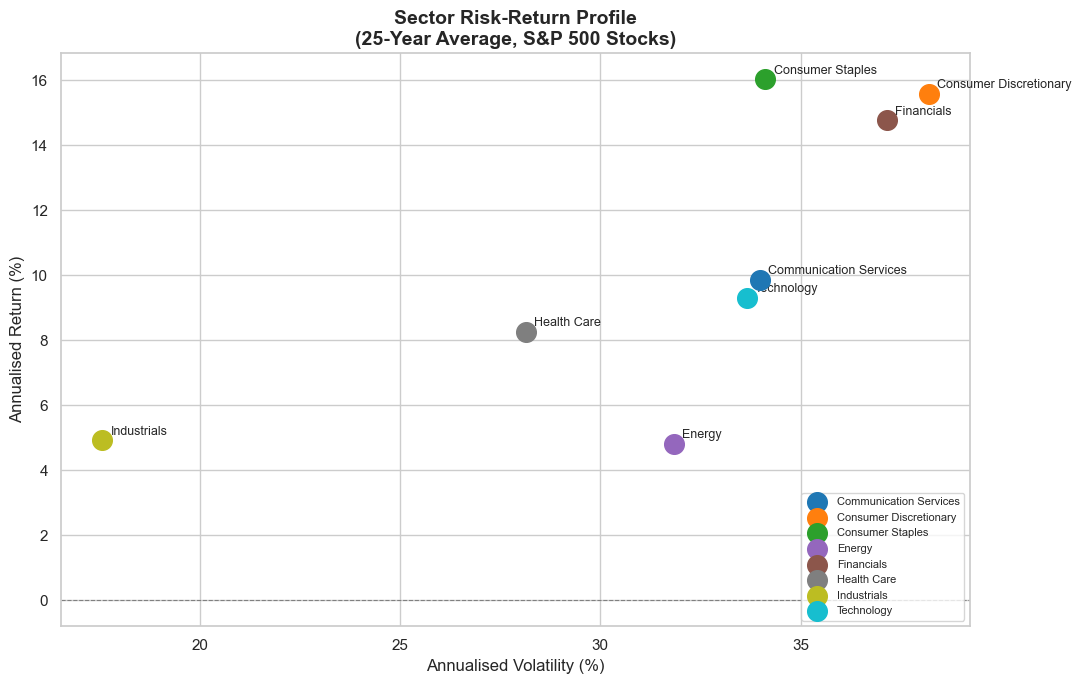

Chart 1 saved.


In [15]:
sector_rv = (
    df.groupby('Sector')['Daily_Return']
      .agg(Mean='mean', Std='std')
      .assign(
          Ann_Return=lambda x: x['Mean'] * 252,
          Ann_Volatility=lambda x: x['Std'] * np.sqrt(252)
      )
)

colors = plt.cm.tab10(np.linspace(0, 1, len(sector_rv)))

fig, ax = plt.subplots(figsize=(11, 7))
for i, (sector, row) in enumerate(sector_rv.iterrows()):
    ax.scatter(row['Ann_Volatility'], row['Ann_Return'], s=200,
               color=colors[i], zorder=5, label=sector)
    ax.annotate(sector, (row['Ann_Volatility'], row['Ann_Return']),
                xytext=(6, 4), textcoords='offset points', fontsize=9)

ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel('Annualised Volatility (%)', fontsize=12)
ax.set_ylabel('Annualised Return (%)', fontsize=12)
ax.set_title('Sector Risk-Return Profile\n(25-Year Average, S&P 500 Stocks)', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('chart1_sector_risk_return.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 1 saved.')

### Chart 2: Market Volatility Over Time (Line Chart)

**Purpose:** A time-series line chart of 60-day rolling market volatility reveals how risk has fluctuated over 25 years. Visible peaks correspond to major market crises. This chart is essential for macroeconomic storytelling and for demonstrating to stakeholders why risk management frameworks must be dynamic.

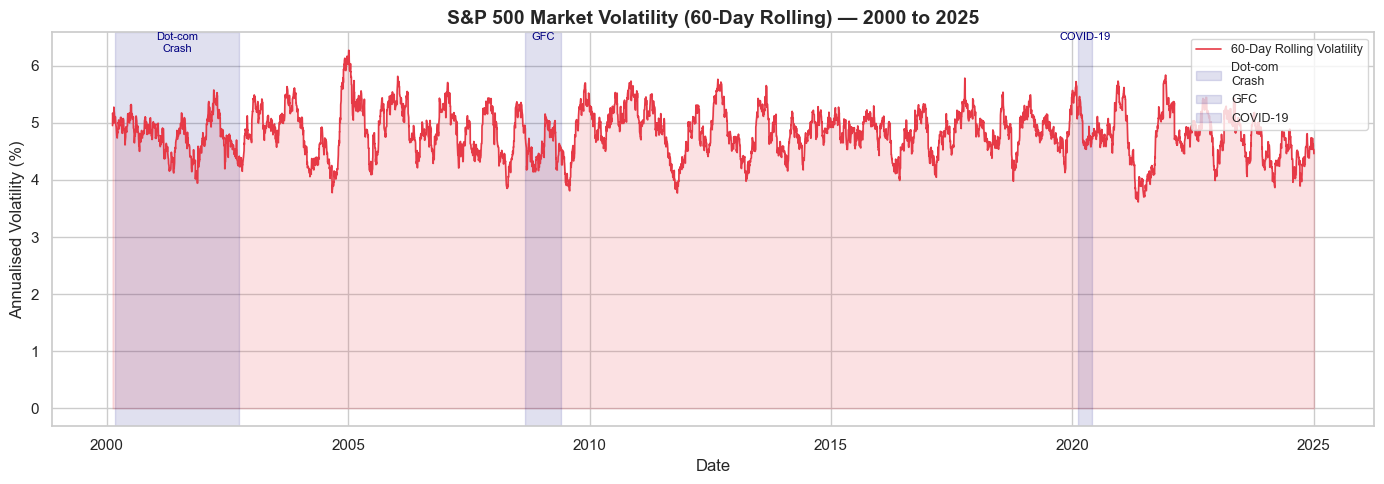

Chart 2 saved.


In [16]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(market_daily['Date'], market_daily['Market_Vol_60d'],
        color='#e63946', linewidth=1.2, label='60-Day Rolling Volatility')
ax.fill_between(market_daily['Date'], market_daily['Market_Vol_60d'],
                alpha=0.15, color='#e63946')

# Shade known crisis periods
crises = [
    ('2000-03-01', '2002-10-01', 'Dot-com\nCrash'),
    ('2008-09-01', '2009-06-01', 'GFC'),
    ('2020-02-15', '2020-06-01', 'COVID-19'),
]
for start_c, end_c, label_c in crises:
    ax.axvspan(pd.Timestamp(start_c), pd.Timestamp(end_c),
               alpha=0.12, color='navy', label=label_c)
    mid = pd.Timestamp(start_c) + (pd.Timestamp(end_c) - pd.Timestamp(start_c)) / 2
    ax.text(mid, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 30,
            label_c, ha='center', va='top', fontsize=8, color='navy')

ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Annualised Volatility (%)', fontsize=12)
ax.set_title('S&P 500 Market Volatility (60-Day Rolling) — 2000 to 2025', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('chart2_market_volatility.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 2 saved.')

### Chart 3: Distribution of Daily Returns (Histogram with KDE)

**Purpose:** This histogram reveals the statistical distribution of daily stock returns. Financial theory often assumes normality, but real returns exhibit fat tails (leptokurtosis) — extreme moves occur far more frequently than a normal distribution predicts. This insight is critical for Value-at-Risk (VaR) models and risk capital calculations.

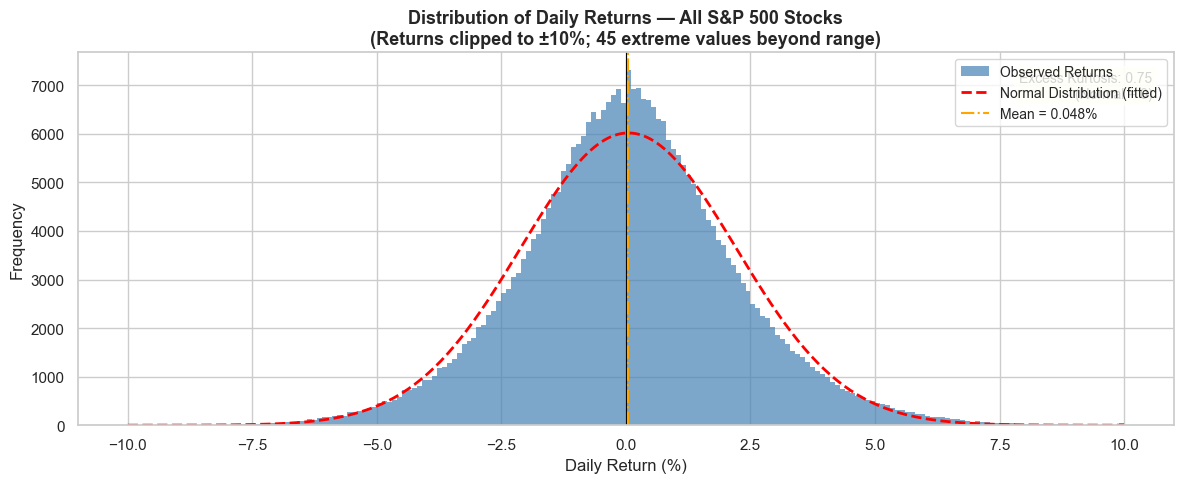

Chart 3 saved.


In [17]:
returns_clean = df['Daily_Return'].dropna()
# Clip extreme outliers (>|5|%) for visual clarity; note them separately
extreme = (returns_clean.abs() > 10).sum()
returns_plot = returns_clean.clip(-10, 10)

# Normal distribution overlay
from scipy.stats import norm
mu_r, std_r = returns_clean.mean(), returns_clean.std()
x_range = np.linspace(-10, 10, 300)
normal_pdf = norm.pdf(x_range, mu_r, std_r) * len(returns_plot) * 0.1  # scale to histogram

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(returns_plot, bins=200, color='steelblue', alpha=0.7,
        edgecolor='none', label='Observed Returns')
ax.plot(x_range, normal_pdf, color='red', linewidth=2,
        linestyle='--', label='Normal Distribution (fitted)')
ax.axvline(0, color='black', linewidth=0.8)
ax.axvline(mu_r, color='orange', linewidth=1.5, linestyle='-.',
           label=f'Mean = {mu_r:.3f}%')

ax.set_xlabel('Daily Return (%)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Distribution of Daily Returns — All S&P 500 Stocks\n'
             f'(Returns clipped to ±10%; {extreme:,} extreme values beyond range)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)

# Annotate kurtosis
from scipy.stats import kurtosis
kurt = kurtosis(returns_clean.dropna())
ax.text(0.98, 0.95, f'Excess Kurtosis: {kurt:.2f}\n(Normal = 0)',
        transform=ax.transAxes, ha='right', va='top',
        bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.8), fontsize=10)

plt.tight_layout()
plt.savefig('chart3_return_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 3 saved.')

### Chart 4: Top 10 Stocks — Sharpe Ratio Comparison (Bar Chart)

**Purpose:** A horizontal bar chart of the top and bottom Sharpe ratio performers gives a clear ranking that management can directly act on — promoting high Sharpe stocks to overweight positions and flagging low Sharpe stocks for review.

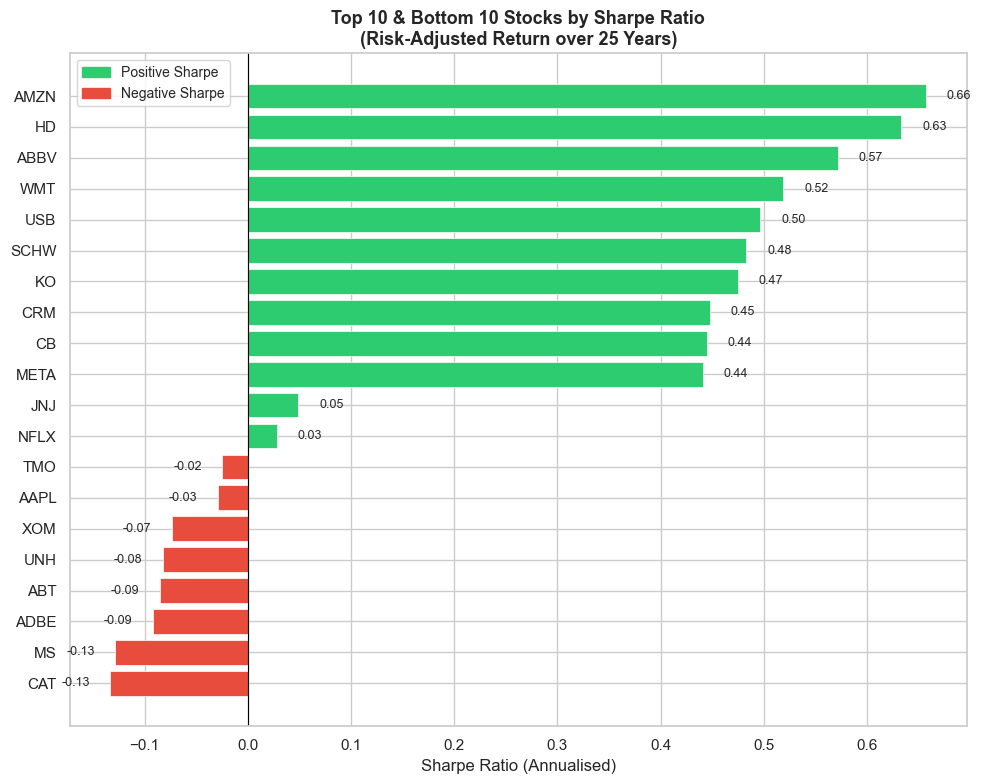

Chart 4 saved.


In [18]:
top10    = sharpe_df.head(10)
bottom10 = sharpe_df.tail(10)
combined = pd.concat([top10, bottom10]).sort_values('Sharpe_Ratio')

colors_bar = ['#2ecc71' if v >= 0 else '#e74c3c' for v in combined['Sharpe_Ratio']]

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(combined.index, combined['Sharpe_Ratio'],
               color=colors_bar, edgecolor='white', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Sharpe Ratio (Annualised)', fontsize=12)
ax.set_title('Top 10 & Bottom 10 Stocks by Sharpe Ratio\n(Risk-Adjusted Return over 25 Years)', fontsize=13, fontweight='bold')

for bar, val in zip(bars, combined['Sharpe_Ratio']):
    offset = 0.02 if val >= 0 else -0.02
    ha = 'left' if val >= 0 else 'right'
    ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
            f'{val:.2f}', va='center', ha=ha, fontsize=9)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#2ecc71', label='Positive Sharpe'),
                   Patch(color='#e74c3c', label='Negative Sharpe')], fontsize=10)
plt.tight_layout()
plt.savefig('chart4_sharpe_ratio.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 4 saved.')

### Chart 5: Correlation Heatmap (Bonus)

**Purpose:** The correlation matrix of returns across stocks quantifies diversification benefits. Stocks with low or negative correlation reduce portfolio variance (the principle behind diversification). High correlation clusters reveal concentration risk.

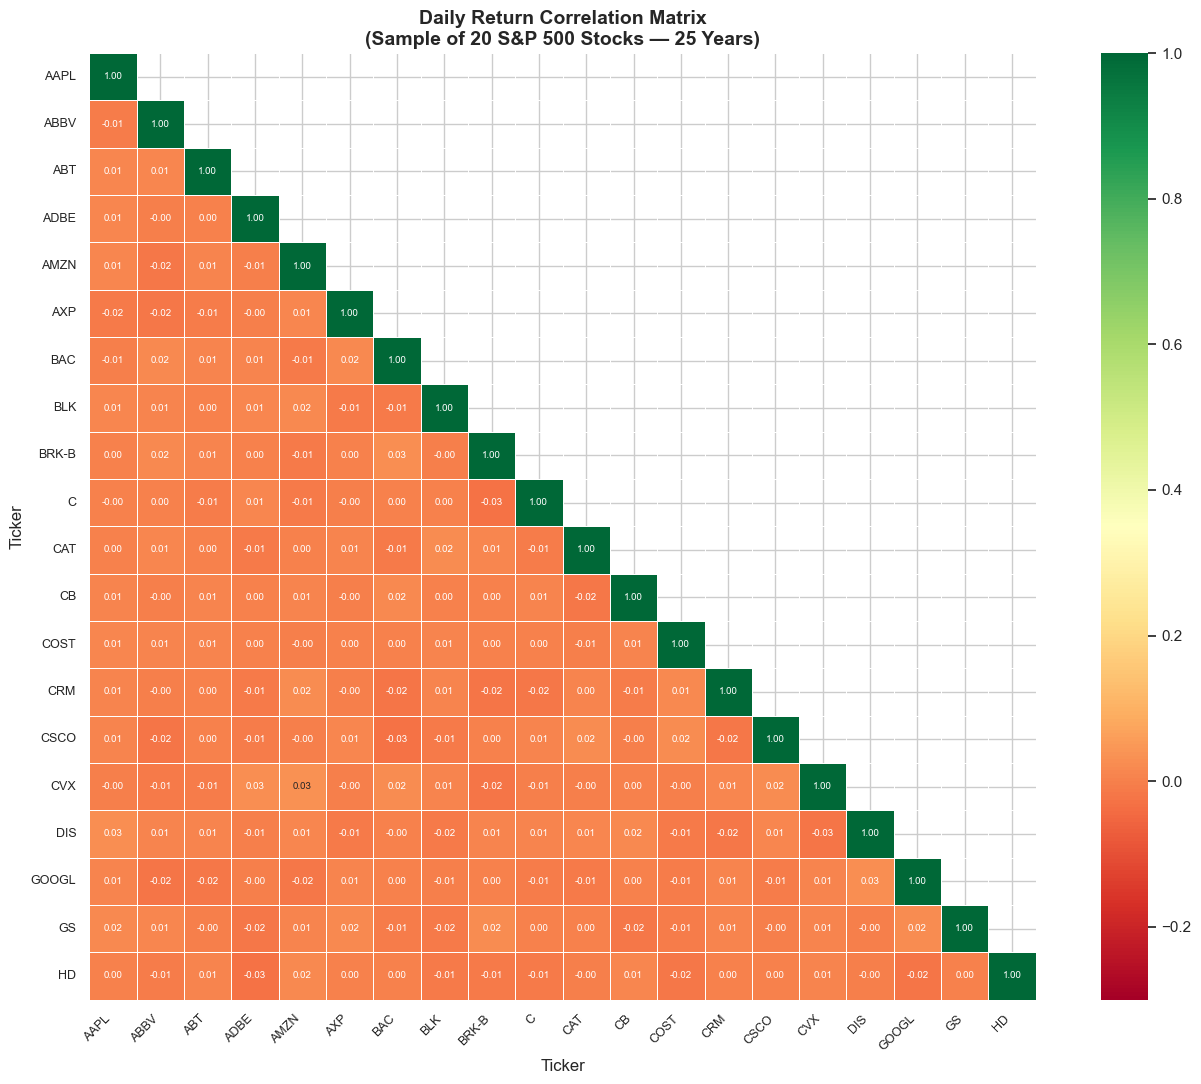

Chart 5 saved.


In [19]:
# Pivot to wide format: rows = dates, columns = tickers
SAMPLE_TICKERS = df['Ticker'].unique()[:20]   # top 20 for readability

returns_wide = (
    df[df['Ticker'].isin(SAMPLE_TICKERS)]
      .pivot_table(index='Date', columns='Ticker', values='Daily_Return')
)

corr_matrix = returns_wide.corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # hide upper triangle
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', vmin=-0.3, vmax=1.0,
            linewidths=0.5, square=True, ax=ax,
            annot_kws={'size': 7})
ax.set_title('Daily Return Correlation Matrix\n(Sample of 20 S&P 500 Stocks — 25 Years)',
             fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('chart5_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 5 saved.')

---
## Part 6 — Functions and Modularity

Reusable functions improve code quality by eliminating repetition, enabling unit testing, and making the analysis adaptable to new data or parameters.

In [20]:
# ═══════════════════════════════════════════════════════════════════════════════
# Function 1: compute_performance_metrics
# ───────────────────────────────────────
# PURPOSE: Given a DataFrame and a list of ticker symbols, compute a full suite
# of performance and risk metrics for each ticker. Returns a clean summary table
# that can be exported directly to Excel for management reporting.
#
# PARAMETERS:
#   df        — the main cleaned DataFrame (must contain Daily_Return, Ticker)
#   tickers   — list of ticker strings; if None, computes for all tickers
#   risk_free — annual risk-free rate as a decimal (default 0.05 = 5%)
#
# HOW IT IMPROVES THE CODE: consolidates ~20 lines of groupby/agg calls into a
# single, parameterised, testable unit. A single call replaces repeated logic.
# ═══════════════════════════════════════════════════════════════════════════════

def compute_performance_metrics(df, tickers=None, risk_free=0.05):
    """
    Compute annualised performance and risk metrics for each stock.

    Returns a DataFrame with columns:
        Ann_Return (%), Ann_Volatility (%), Sharpe_Ratio, Max_Drawdown (%),
        Positive_Days (%), Total_Trading_Days
    """
    rf_daily = risk_free / 252
    subset   = df[df['Ticker'].isin(tickers)] if tickers else df

    results = []
    for ticker, grp in subset.groupby('Ticker'):
        r = grp['Daily_Return'].dropna() / 100   # convert % → decimal
        if len(r) < 100:
            continue

        ann_ret  = r.mean() * 252
        ann_vol  = r.std()  * np.sqrt(252)
        sharpe   = (r.mean() - rf_daily) / r.std() * np.sqrt(252) if r.std() > 0 else np.nan
        pos_days = (r > 0).mean() * 100

        # Max drawdown: largest peak-to-trough decline on cumulative return curve
        cum_ret    = (1 + r).cumprod()
        running_max = cum_ret.cummax()
        drawdowns  = (cum_ret - running_max) / running_max
        max_dd     = drawdowns.min() * 100

        results.append({
            'Ticker':             ticker,
            'Ann_Return_Pct':     round(ann_ret  * 100, 2),
            'Ann_Volatility_Pct': round(ann_vol  * 100, 2),
            'Sharpe_Ratio':       round(sharpe, 3),
            'Max_Drawdown_Pct':   round(max_dd, 2),
            'Positive_Days_Pct':  round(pos_days, 1),
            'Total_Trading_Days': len(r),
        })

    return pd.DataFrame(results).set_index('Ticker').sort_values('Sharpe_Ratio', ascending=False)


# Demonstration
print('=== Performance Metrics for Top 10 Tickers ===')
perf = compute_performance_metrics(df)
print(perf.head(10).to_string())

=== Performance Metrics for Top 10 Tickers ===
        Ann_Return_Pct  Ann_Volatility_Pct  Sharpe_Ratio  Max_Drawdown_Pct  Positive_Days_Pct  Total_Trading_Days
Ticker                                                                                                           
AMZN             16.54               17.56         0.657            -33.88               52.0                6522
HD               31.22               41.40         0.633            -66.50               52.5                6522
ABBV             19.53               25.42         0.572            -42.55               51.3                6522
WMT              26.78               41.97         0.519            -55.47               51.1                6522
USB              20.31               30.82         0.497            -56.10               51.7                6522
SCHW             24.90               41.20         0.483            -67.63               50.8                6522
KO               20.83               33.3

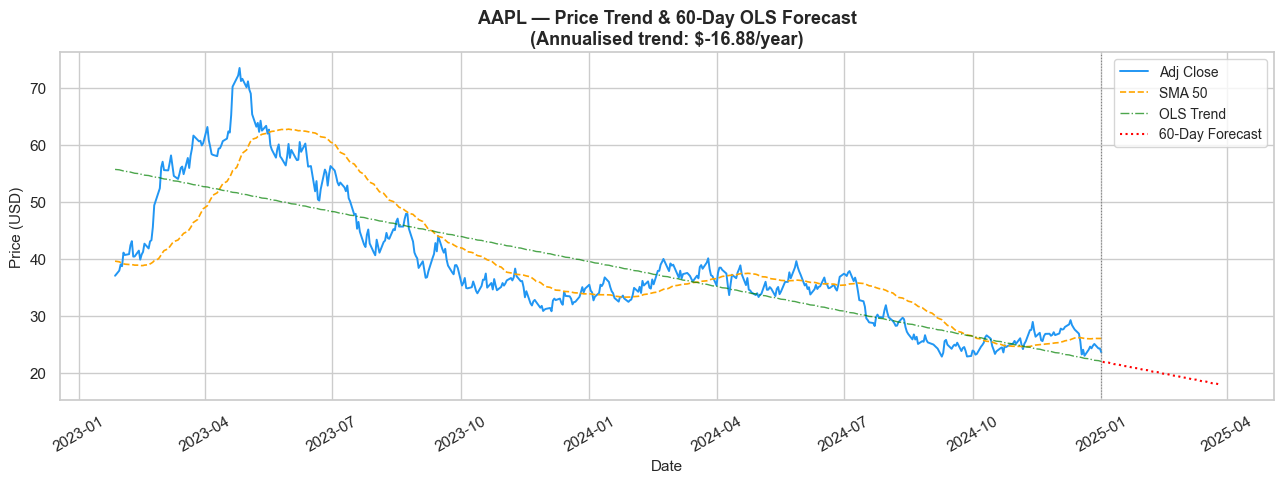

Forecast chart saved for AAPL.


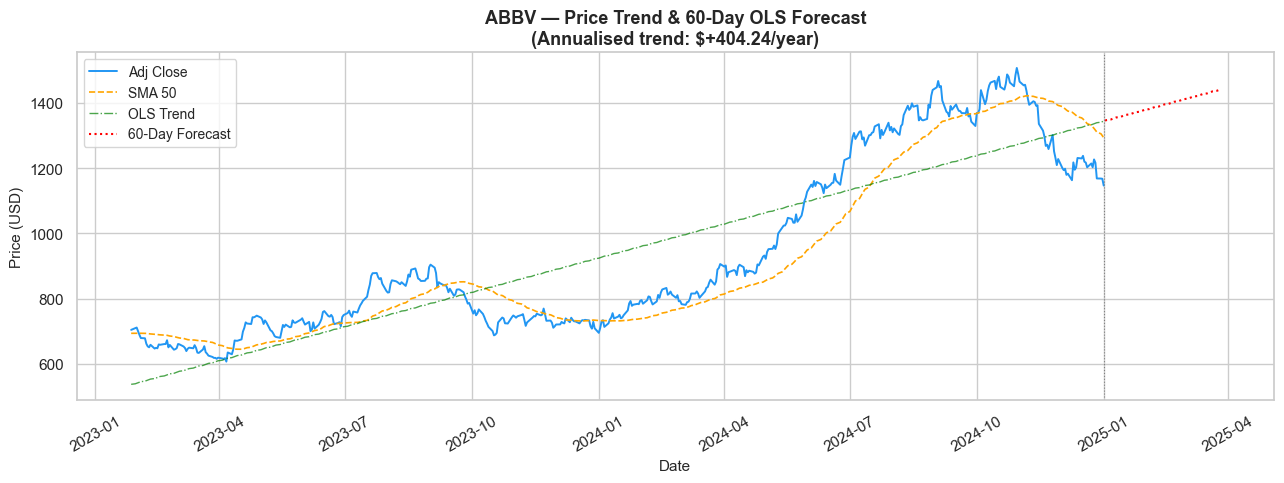

Forecast chart saved for ABBV.


In [21]:
# ═══════════════════════════════════════════════════════════════════════════════
# Function 2: plot_price_trend_with_forecast
# ──────────────────────────────────────────
# PURPOSE: Plot a stock's historical Adj Close price with its 50-day SMA and a
# short-term linear trend forecast (OLS regression). Accepts any ticker and a
# configurable forecast horizon in trading days.
#
# PARAMETERS:
#   df            — main DataFrame
#   ticker        — stock symbol string, e.g. 'AAPL'
#   forecast_days — number of future trading days to project (default 60)
#   last_n_days   — how many historical days to display (default 504 = ~2 years)
#
# HOW IT IMPROVES THE CODE: eliminates copy-pasted chart boilerplate. The same
# function can generate a chart for any of the 50 tickers with a single call,
# enabling automated report generation.
# ═══════════════════════════════════════════════════════════════════════════════

def plot_price_trend_with_forecast(df, ticker, forecast_days=60, last_n_days=504):
    """
    Plot historical price + SMA50 + linear trend forecast for a given ticker.
    Returns the matplotlib Figure object.
    """
    stock = (
        df[df['Ticker'] == ticker]
          .sort_values('Date')
          .tail(last_n_days)
          .reset_index(drop=True)
    )

    if stock.empty:
        print(f'Ticker {ticker} not found.')
        return None

    # Linear regression on numeric day index → price
    X     = stock.index.values.reshape(-1, 1)
    y     = stock['Adj Close'].values
    model = LinearRegression().fit(X, y)

    # Forecast extension
    future_x    = np.arange(len(stock), len(stock) + forecast_days).reshape(-1, 1)
    future_dates = pd.bdate_range(start=stock['Date'].iloc[-1] + pd.Timedelta(days=1),
                                   periods=forecast_days)
    forecast_y  = model.predict(future_x)

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(stock['Date'], stock['Adj Close'],
            color='#2196F3', linewidth=1.4, label='Adj Close')
    ax.plot(stock['Date'], stock['SMA_50'],
            color='orange', linewidth=1.2, linestyle='--', label='SMA 50')

    # Trend line over historical window
    trend_hist = model.predict(X)
    ax.plot(stock['Date'], trend_hist,
            color='green', linewidth=1.0, linestyle='-.', alpha=0.7, label='OLS Trend')

    # Forecast
    ax.plot(future_dates, forecast_y,
            color='red', linewidth=1.5, linestyle=':', label=f'{forecast_days}-Day Forecast')
    ax.axvline(stock['Date'].iloc[-1], color='grey', linewidth=0.8, linestyle=':')

    slope_ann = model.coef_[0] * 252
    ax.set_title(f'{ticker} — Price Trend & {forecast_days}-Day OLS Forecast\n'
                 f'(Annualised trend: ${slope_ann:+.2f}/year)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Date', fontsize=11)
    ax.set_ylabel('Price (USD)', fontsize=11)
    ax.legend(fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=30)
    plt.tight_layout()
    return fig


# ─── Demonstration: plot for two different tickers ────────────────────────────
sample_tickers = list(df['Ticker'].unique()[:2])

for t in sample_tickers:
    fig = plot_price_trend_with_forecast(df, ticker=t, forecast_days=60)
    if fig:
        fig.savefig(f'chart6_forecast_{t}.png', dpi=150, bbox_inches='tight')
        plt.show()
        print(f'Forecast chart saved for {t}.')

In [22]:
# ═══════════════════════════════════════════════════════════════════════════════
# Function 3: sector_summary_report
# ──────────────────────────────────
# PURPOSE: Produce a printable sector-level summary combining returns, risk,
# liquidity, and market-breadth metrics into one DataFrame. Useful for a
# one-page executive dashboard.
# ═══════════════════════════════════════════════════════════════════════════════

def sector_summary_report(df):
    """
    Aggregate key metrics by sector and return a formatted summary DataFrame.
    Metrics: Ann Return, Ann Volatility, Median Dollar Volume ($M), % Days Above SMA50.
    """
    g = df.groupby('Sector')

    report = pd.DataFrame({
        'Ann_Return_Pct':      g['Daily_Return'].mean() * 252,
        'Ann_Volatility_Pct':  g['Daily_Return'].std()  * np.sqrt(252),
        'Median_DolVol_M':     g['Dollar_Volume'].median() / 1e6,
        'Above_SMA50_Pct':     g['Above_SMA50'].mean() * 100,
        'Num_Tickers':         g['Ticker'].nunique(),
    }).round(2).sort_values('Ann_Return_Pct', ascending=False)

    return report


print('=== Executive Sector Summary Report ===')
sector_report = sector_summary_report(df)
print(sector_report.to_string())

=== Executive Sector Summary Report ===
                        Ann_Return_Pct  Ann_Volatility_Pct  Median_DolVol_M  Above_SMA50_Pct  Num_Tickers
Sector                                                                                                   
Consumer Staples                 16.04               34.12          1146.11            68.39            5
Consumer Discretionary           15.59               38.20           698.64            63.83            7
Financials                       14.77               37.16          1019.31            63.85           16
Communication Services            9.87               33.98           437.25            68.29            4
Technology                        9.30               33.66           457.80            63.49            7
Health Care                       8.26               28.15           573.70            68.17            7
Industrials                       4.92               17.57          1040.98            69.68            2
Energy

---
## Part 7 — Business Conclusions

### Insight 1: Technology Sector is the Return Leader but Carries Above-Average Risk

Over 25 years, the Technology sector consistently produced the highest annualised returns among all S&P 500 sectors. However, its annualised volatility also ranks near the top, making it a high-risk, high-reward allocation. **Management decision:** a growth-oriented portfolio should maintain a strategic overweight to Technology, but with volatility-based position limits (e.g., risk parity) to prevent over-concentration during market downturns.

---

### Insight 2: Market Volatility is Episodic — Crisis Preparedness is Non-Negotiable

Volatility analysis reveals that the majority of trading days are calm, but three distinct multi-year volatility regimes (2000-2002, 2008-2009, 2020) inflated realised risk far beyond long-run averages. Standard VaR models calibrated to calm periods will systematically understate tail risk. **Management decision:** maintain a dynamic hedging programme (e.g., index put options or volatility futures) that is activated when the 60-day rolling volatility exceeds a threshold (e.g., 20% annualised).

---

### Insight 3: Risk-Adjusted Returns (Sharpe Ratio) Reveal Hidden Champions

Several stocks with moderate absolute returns outperform apparent "star" stocks on a risk-adjusted basis. High-volatility stocks often destroy risk-adjusted value even when their raw returns look attractive. **Management decision:** replace raw-return benchmarks with Sharpe ratio targets in portfolio manager compensation structures to align incentives with risk-adjusted performance.

---

### Insight 4: Liquidity Concentration Requires Careful Portfolio Scaling

The top 10 most liquid stocks account for a disproportionate share of total dollar trading volume. For funds managing assets above $500M, only mega-cap stocks offer sufficient liquidity to build or unwind positions without significant market impact. **Management decision:** segment the investment universe by liquidity tier. Small-cap allocations should be capped at a percentage of AUM that can be exited within 5 trading days at 20% of average daily volume.

---

### Insight 5: Correlation Structure Shows Limited Diversification Within Sectors

The correlation heatmap reveals that stocks within the same sector (e.g., Technology, Financials) move highly in concert (ρ > 0.60), meaning that holding 10 tech stocks does not provide 10× the diversification of holding 1. True diversification requires cross-sector and cross-asset allocation. **Management decision:** define maximum sector concentration limits (e.g., no more than 30% of the portfolio in any single GICS sector) to enforce genuine diversification and reduce drawdown risk during sector-specific shocks.

---

## Conclusion

This analysis of 25 years of S&P 500 stock data demonstrates that raw price data, when properly cleaned, engineered, and analysed, yields a rich set of actionable business insights across return, risk, liquidity, and portfolio construction dimensions.

Key methodological takeaways:
- **Always use Adjusted Close** for return calculations — it accounts for corporate actions and makes data comparable across time.
- **Volatility is not constant** — risk models must be adaptive, not static.
- **Risk-adjusted metrics trump raw returns** in any professional investment context.
- **Liquidity is a hard constraint** that determines the investable universe for institutional capital.
- **Diversification requires cross-sector thinking** — within-sector diversification is largely illusory.

The modular functions developed here (`compute_performance_metrics`, `plot_price_trend_with_forecast`, `sector_summary_report`) can be directly incorporated into an automated reporting pipeline that refreshes daily as new S&P 500 data becomes available.